In [136]:
import pandas
tracts = pandas.read_csv("Neighborhoods_.csv", dtype={"geoid10": str})

def census_to_neighborhood(census_tract):
    if pandas.isna(census_tract):
        return None
    neighborhoods = tracts[tracts["geoid10"].str.startswith(census_tract)]
    if neighborhoods.empty:
        return None
    hood = neighborhoods.iloc[0]["hood"]
    return hood

print(census_to_neighborhood("42003060300"))

Lower Lawrenceville


In [239]:
import matplotlib.pyplot as plt
ratios = pandas.read_csv("sidewalkstreetratiotract.csv", dtype={"Tract": str})
ratios["Hood"] = ratios["Tract"]
ratios["Hood"] = ratios["Tract"].apply(census_to_neighborhood)
ratios = ratios.dropna(subset=["Hood"])
ratios["Ratio"] = pandas.to_numeric(ratios["Ratio"], errors="coerce")
ratios = ratios.sort_values("Ratio")
ratios.head(50)

,Tract,SidewalkStepLFt,StreetLFt,Ratio,Hood
105,42003310300,1890.155427,39824.97614,0.047462,New Homestead
104,42003310200,20389.007390,96125.50497,0.212108,Lincoln Place
89,42003261200,8352.955184,32732.39614,0.255189,Summer Hill
78,42003202300,34934.687060,93150.63236,0.375034,Banksville
378,42003563100,44946.943610,71484.65996,0.628763,Westwood
92,42003262000,50345.485990,61431.73938,0.819535,Spring Hill-City View
376,42003562900,73538.145780,86565.66943,0.849507,Hays
2,42003020300,92663.562380,107882.68170,0.858929,Strip District
69,42003191100,52914.885480,61502.27796,0.860373,Duquesne Heights
377,42003563000,63351.590520,73428.01634,0.862771,Fairywood


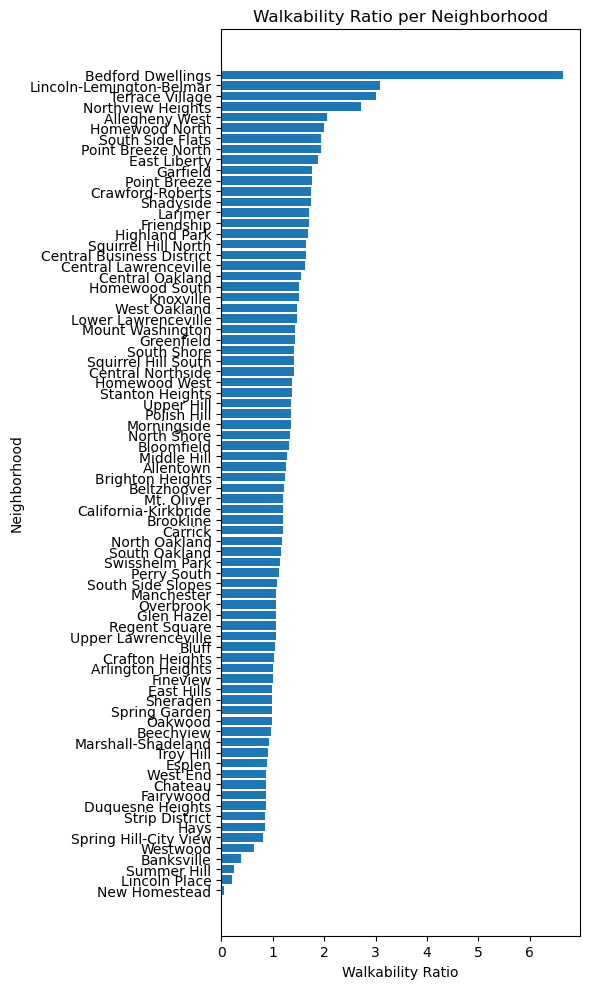

In [258]:
plt.figure(figsize=(6,10))
plt.barh(ratios["Hood"],ratios["Ratio"])
plt.xlabel("Walkability Ratio")
plt.ylabel("Neighborhood")
plt.title("Walkability Ratio per Neighborhood")
plt.tight_layout()
plt.show()